# Miniproyecto 2 - Clasificación de Sentimientos con Redes Recurrentes (RNN)


# 1. Introducción y contexto

El análisis de sentimientos en reseñas de cine es una tarea clásica pero desafiante en el procesamiento de lenguaje natural (NLP). En plataformas como IMDb, las opiniones de los usuarios reflejan valoraciones personales que pueden incluir elogios, críticas severas, expresiones coloquiales, dobles negaciones y giros de opinión complejos. El objetivo de este proyecto es construir un clasificador automático capaz de leer el texto de una reseña cinematográfica y determinar si su polaridad general es **positiva (clase 1)** o **negativa (clase 0)**.

A diferencia de los modelos basados en bolsas de palabras o frecuencias unigramas, las **Redes Neuronales Recurrentes (RNN)** son especialmente adecuadas para modelar datos secuenciales, ya que tienen la capacidad de almacenar y recordar información previa a lo largo del texto. En este laboratorio exploraremos el uso de dos variantes recurrentes con mecanismos de compuertas: la arquitectura **Long Short-Term Memory (LSTM)** y la arquitectura **Gated Recurrent Unit (GRU)**, evaluando su precisión, eficiencia computacional y comportamiento frente a sobreajuste.


## 1.1. Arquitectura Long Short-Term Memory (LSTM) y Gated Recurrent Unit (GRU)

Las redes recurrentes tradicionales sufren del problema de desvanecimiento del gradiente (*vanishing gradient*) al procesar secuencias largas. Para superar esta limitación:
- **LSTM:** Utiliza una celda de memoria separada (*cell state*) y tres compuertas: la compuerta de olvido (*forget gate*), que decide qué información pasada descartar; la compuerta de entrada (*input gate*), que incorpora nueva información relevante; y la compuerta de salida (*output gate*), que determina qué parte del estado se transmite al siguiente paso.
- **GRU:** Propone una formulación más compacta que une el estado oculto y de celda en una sola representación, gobernada por dos compuertas: actualización (*update gate*) y reinicio (*reset gate*). Al tener menos parámetros, suele entrenar más rápido y con menor riesgo de sobreajuste cuando se combina con regularización por *Dropout*.


# 2. Importar y acondicionar datos


In [1]:
# Celda con la importación de librerías

import os
import re
from time import time
import copy
import string
from collections import Counter

import pandas as pd               # Librería para manejo de dataframes
import numpy as np                # Librería para trabajar con datos matriciales
import matplotlib.pyplot as plt   # Librería de visualización

# PyTorch
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader   # Utilidades para construir el pipeline de datos

# Sklearn
from sklearn.model_selection import train_test_split     # División de datos
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,  # Métricas de validación
    confusion_matrix, ConfusionMatrixDisplay, roc_auc_score
)

np.random.seed(42)            # Inicializar semilla para números aleatorios
torch.manual_seed(42)         # Establecer semilla para el generador de números aleatorios de PyTorch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")  # Seleccionar GPU si está disponible
print(f"Dispositivo utilizado: {device}")


Dispositivo utilizado: cpu


In [2]:
# Se lee el archivo de datos y se convierte en un DataFrame,
# una estructura especial que representa los datos en forma de tabla,
# facilitando su manipulación y análisis.

dataset_path = os.path.join('archive', 'movie.csv')
if not os.path.exists(dataset_path):
    dataset_path = os.path.join('..', 'archive', 'movie.csv')

df = pd.read_csv(dataset_path)
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   text    40000 non-null  object
 1   label   40000 non-null  int64 
dtypes: int64(1), object(1)
memory usage: 625.1+ KB


Conteo de valores nulos por columna:
text     0
label    0
dtype: int64

Distribución de etiquetas de polaridad (0: Negativo, 1: Positivo):
label
0    20019
1    19981
Name: count, dtype: int64


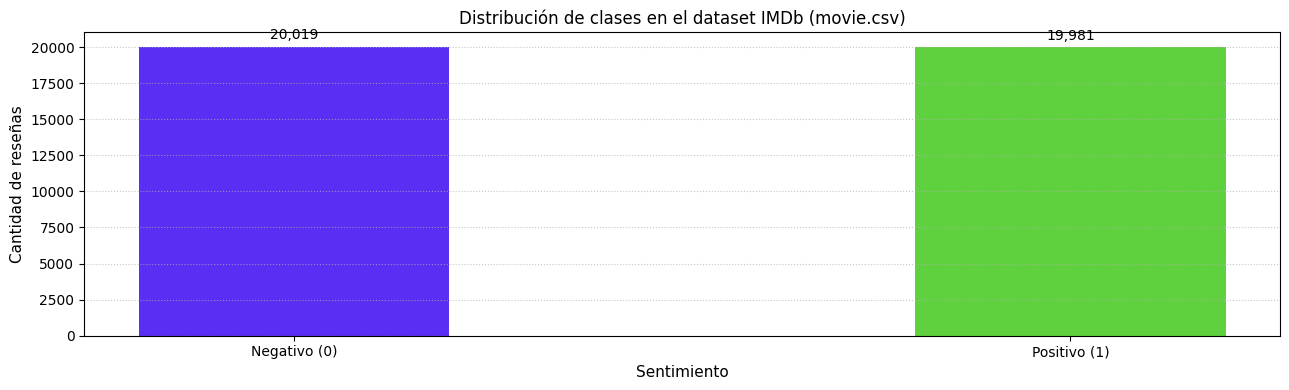

In [3]:
# Distribución de las etiquetas en el conjunto de observaciones
print("Conteo de valores nulos por columna:")
print(df.isnull().sum())

print("\nDistribución de etiquetas de polaridad (0: Negativo, 1: Positivo):")
conteo_clases = df['label'].value_counts()
print(conteo_clases)

# Visualización gráfica de la distribución de clases
plt.figure(figsize=(13, 4))
barras = plt.bar(['Negativo (0)', 'Positivo (1)'], conteo_clases.values, color=['#5a2ff4', '#60d13e'], width=0.4)
plt.title('Distribución de clases en el dataset IMDb (movie.csv)', fontsize=12)
plt.xlabel('Sentimiento', fontsize=11)
plt.ylabel('Cantidad de reseñas', fontsize=11)
plt.grid(axis='y', linestyle=':', alpha=0.7)

for barra in barras:
    yval = barra.get_height()
    plt.text(barra.get_x() + barra.get_width()/2, yval + 300, f"{yval:,}", ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()


A continuación, realizamos la preparación de los datos textuales. Primero, implementamos una función de saneamiento para remover etiquetas HTML, signos de puntuación y URLs. Luego, seleccionamos una muestra balanceada de 20,000 reseñas para entrenar de forma eficiente en CPU y construimos el vocabulario con las 10,000 palabras más frecuentes. Finalmente, aplicamos relleno por la izquierda (*pre-padding*) para que cada reseña tenga exactamente 150 pasos temporales, asegurando que el último estado de la RNN procese las palabras de cierre de la opinión.


In [4]:
def clean_text(text):
    """
    Función que realiza la limpieza de texto eliminando etiquetas HTML,
    signos de puntuación, URLs y convirtiendo a minúsculas.
    """
    text = text.lower()                                            # Minúsculas
    text = re.sub(r'<br\s*/?>', ' ', text)                         # Etiquetas HTML
    text = re.sub(r'https?://\S+|www\.\S+', '', text)               # URLs
    text = re.sub(f'[{re.escape(string.punctuation)}]', ' ', text)   # Signos de puntuación
    text = re.sub(r'\s+', ' ', text).strip()                       # Espacios redundantes
    return text

# Muestra balanceada de 20,000 observaciones (10,000 por clase)
df_sample = df.groupby('label', group_keys=False).apply(
    lambda x: x.sample(n=10000, random_state=42)
).reset_index(drop=True)

# Limpiar texto de las reseñas
df_sample['cleaned_text'] = df_sample['text'].apply(clean_text)

print(f"Dimensión de la muestra seleccionada: {len(df_sample)}")
print("Ejemplo de reseña original:")
print(df_sample['text'].iloc[0][:200] + "...")
print("\nEjemplo de reseña limpia:")
print(df_sample['cleaned_text'].iloc[0][:200] + "...")


C:\Users\josar\AppData\Local\Temp\ipykernel_19352\3071244907.py:14: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_sample = df.groupby('label', group_keys=False).apply(


Dimensión de la muestra seleccionada: 20000
Ejemplo de reseña original:
I went to see this movie with the most positive expectations. I had seen Jacquet's previous movie (march of the penguins) and had heard a very positive review of this one on the radio. However, I was ...

Ejemplo de reseña limpia:
i went to see this movie with the most positive expectations i had seen jacquet s previous movie march of the penguins and had heard a very positive review of this one on the radio however i was sever...


In [5]:
# Tokenización y construcción del vocabulario de palabras
tokenized_texts = [text.split() for text in df_sample['cleaned_text']]
word_counts = Counter(word for doc in tokenized_texts for word in doc)

VOCAB_SIZE = 10000   # Tamaño del vocabulario
MAX_SEQ_LEN = 150    # Longitud fija de la secuencia

# Índices reservados: 0 para <PAD> y 1 para <UNK>
vocab = {"<PAD>": 0, "<UNK>": 1}
for word, _ in word_counts.most_common(VOCAB_SIZE - 2):
    vocab[word] = len(vocab)

print(f"Tamaño del vocabulario: {len(vocab)} tokens")
print(f"Top 10 palabras más frecuentes: {[w for w, _ in word_counts.most_common(10)]}")

def text_to_sequence(tokens, vocab_dict, max_len=150):
    """
    Convierte una lista de palabras a un arreglo de índices con pre-padding (relleno a la izquierda).
    """
    seq = [vocab_dict.get(word, vocab_dict["<UNK>"]) for word in tokens[-max_len:]]
    if len(seq) < max_len:
        seq = [vocab_dict["<PAD>"]] * (max_len - len(seq)) + seq
    return seq

# Vectorizar todo el conjunto
X_all = np.array([text_to_sequence(toks, vocab, MAX_SEQ_LEN) for toks in tokenized_texts])
y_all = df_sample['label'].values

print(f"Dimensión de la matriz de secuencias X: {X_all.shape}")
print(f"Dimensión del vector de etiquetas y: {y_all.shape}")


Tamaño del vocabulario: 10000 tokens
Top 10 palabras más frecuentes: ['the', 'and', 'a', 'of', 'to', 'is', 'it', 'in', 'i', 'this']
Dimensión de la matriz de secuencias X: (20000, 150)
Dimensión del vector de etiquetas y: (20000,)


A continuación dividimos los datos temporalmente asignando 70% para entrenamiento, 15% para validación y 15% para pruebas, con proporciones de clase idénticas. Luego creamos los `DataLoader` de PyTorch para alimentar los modelos en lotes de tamaño 64.


In [6]:
# División en conjunto de entrenamiento, validación y prueba
X_train, X_temp, y_train, y_temp, idx_train, idx_temp = train_test_split(
    X_all, y_all, np.arange(len(df_sample)),
    test_size=0.30, random_state=42, stratify=y_all
)

X_val, X_test, y_val, y_test, idx_val, idx_test = train_test_split(
    X_temp, y_temp, idx_temp,
    test_size=0.50, random_state=42, stratify=y_temp
)

# Imprimimos las dimensiones de los conjuntos
print(f"Dimensión del conjunto general de observaciones {X_all.shape}")
print(f"Dimensión del conjunto de entrenamiento {X_train.shape}")
print(f"Dimensión del conjunto de validación {X_val.shape}")
print(f"Dimensión del conjunto de prueba {X_test.shape}")

# DataLoaders para entrenar por lotes de tamaño 64
BATCH_SIZE = 64

train_dataset = TensorDataset(torch.tensor(X_train, dtype=torch.long), torch.tensor(y_train, dtype=torch.float32))
val_dataset   = TensorDataset(torch.tensor(X_val, dtype=torch.long),   torch.tensor(y_val, dtype=torch.float32))
test_dataset  = TensorDataset(torch.tensor(X_test, dtype=torch.long),  torch.tensor(y_test, dtype=torch.float32))

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False)


Dimensión del conjunto general de observaciones (20000, 150)
Dimensión del conjunto de entrenamiento (14000, 150)
Dimensión del conjunto de validación (3000, 150)
Dimensión del conjunto de prueba (3000, 150)


# 3. Modelado con Redes Recurrentes

En esta sección establecemos las arquitecturas de aprendizaje profundo utilizando redes recurrentes RNN. Implementamos dos variantes: un modelo base con celda **LSTM** y un segundo modelo con celda **GRU** regularizada con *Dropout*, comparando su capacidad predictiva y tiempo de entrenamiento.


## 3.1. Modelo 1: LSTM Estándar

El diseño consta de una capa `nn.Embedding` de 64 dimensiones que proyecta los tokens a un espacio denso continuo, seguida por una capa `nn.LSTM` con 64 unidades ocultas que procesa los 150 pasos temporales y produce un vector de contexto (el último estado oculto $h_T$), finalizando con una capa `nn.Linear` que proyecta a la predicción binaria.


In [7]:
# Modelo LSTM para clasificación binaria
class SentimentLSTM(nn.Module):
    """
    Modelo recurrente basado en LSTM para clasificación de polaridad en texto.
    """
    def __init__(self, vocab_size, embed_dim, hidden_units, pad_idx=0):
        super().__init__()
        # Capa de embedding para representar palabras como vectores densos
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=pad_idx)
        # Capa LSTM con batch_first=True
        self.lstm = nn.LSTM(input_size=embed_dim, hidden_size=hidden_units, batch_first=True)
        # Capa lineal final de salida
        self.output_layer = nn.Linear(hidden_units, 1)

    def forward(self, x):
        # x: [batch, timesteps]
        emb = self.embedding(x)                 # [batch, timesteps, embed_dim]
        _, (h_n, _) = self.lstm(emb)           # h_n: [1, batch, hidden_units]
        out = self.output_layer(h_n[-1])        # [batch, 1]
        return out.squeeze(1)


# Instanciar el modelo y enviarlo al dispositivo (CPU o GPU)
EMBED_DIM = 64
HIDDEN_UNITS = 64

model_lstm = SentimentLSTM(VOCAB_SIZE, EMBED_DIM, HIDDEN_UNITS).to(device)


In [8]:
# Resumen de la arquitectura del modelo
print(model_lstm)

n_params_lstm = sum(p.numel() for p in model_lstm.parameters() if p.requires_grad)
print(f"\nNúmero total de parámetros entrenables: {n_params_lstm:,}")


SentimentLSTM(
  (embedding): Embedding(10000, 64, padding_idx=0)
  (lstm): LSTM(64, 64, batch_first=True)
  (output_layer): Linear(in_features=64, out_features=1, bias=True)
)

Número total de parámetros entrenables: 673,345


In [9]:
# "Compilación" del modelo: en PyTorch el optimizador y la función de pérdida se definen explícitamente
optimizer_lstm = torch.optim.Adam(model_lstm.parameters(), lr=0.001)
criterion = nn.BCEWithLogitsLoss()


En esta etapa procedemos con el entrenamiento utilizando los conjuntos de entrenamiento y validación. Para el entrenamiento implementamos manualmente una estrategia de parada anticipada (*early stopping*) con paciencia de 3 épocas para prevenir el sobreajuste y restaurar los mejores pesos obtenidos.


In [10]:
# Entrenamiento del modelo 1 (LSTM)
start = time()        # Se fija el tiempo inicial en el que está iniciando el entrenamiento

n_epochs = 10
patience = 3
best_val_loss = float('inf')
epochs_no_improve = 0
best_model_state_lstm = None

history_lstm = {'loss': [], 'val_loss': [], 'acc': [], 'val_acc': []}

for epoch in range(n_epochs):
    # Fase de entrenamiento
    model_lstm.train()
    running_loss = 0.0
    correct_train = 0
    total_train = 0

    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer_lstm.zero_grad()
        logits = model_lstm(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer_lstm.step()

        running_loss += loss.item() * xb.size(0)
        preds = (torch.sigmoid(logits) >= 0.5).float()
        correct_train += (preds == yb).sum().item()
        total_train += yb.size(0)

    train_loss = running_loss / total_train
    train_acc = correct_train / total_train

    # Fase de validación
    model_lstm.eval()
    running_val_loss = 0.0
    correct_val = 0
    total_val = 0

    with torch.no_grad():
        for xb, yb in val_loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model_lstm(xb)
            loss = criterion(logits, yb)
            running_val_loss += loss.item() * xb.size(0)
            preds = (torch.sigmoid(logits) >= 0.5).float()
            correct_val += (preds == yb).sum().item()
            total_val += yb.size(0)

    val_loss = running_val_loss / total_val
    val_acc = correct_val / total_val

    history_lstm['loss'].append(train_loss)
    history_lstm['val_loss'].append(val_loss)
    history_lstm['acc'].append(train_acc)
    history_lstm['val_acc'].append(val_acc)

    print(f"Época {epoch+1:02d}/{n_epochs:02d} — loss: {train_loss:.4f} — acc: {train_acc*100:.2f}% | val_loss: {val_loss:.4f} — val_acc: {val_acc*100:.2f}%")

    # Lógica de parada temprana
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        epochs_no_improve = 0
        best_model_state_lstm = copy.deepcopy(model_lstm.state_dict())
    else:
        epochs_no_improve += 1
        if epochs_no_improve >= patience:
            print(f"Early stopping en la época {epoch+1}: la pérdida de validación no mejoró en {patience} épocas.")
            break

# Restaurar los mejores pesos encontrados durante el entrenamiento
if best_model_state_lstm is not None:
    model_lstm.load_state_dict(best_model_state_lstm)

time_lstm = time() - start
print("El modelo tardó %.2f segundos en entrenar." % time_lstm)


Época 01/10 — loss: 0.6454 — acc: 62.15% | val_loss: 0.5882 — val_acc: 67.83%
Época 02/10 — loss: 0.5279 — acc: 74.22% | val_loss: 0.4779 — val_acc: 78.07%
Época 03/10 — loss: 0.4891 — acc: 77.08% | val_loss: 0.4947 — val_acc: 77.67%
Época 04/10 — loss: 0.4109 — acc: 81.95% | val_loss: 0.4474 — val_acc: 79.87%
Época 05/10 — loss: 0.3478 — acc: 85.31% | val_loss: 0.4292 — val_acc: 82.67%
Época 06/10 — loss: 0.3125 — acc: 87.34% | val_loss: 0.4330 — val_acc: 81.93%
Época 07/10 — loss: 0.2694 — acc: 89.45% | val_loss: 0.4072 — val_acc: 82.93%
Época 08/10 — loss: 0.2360 — acc: 91.09% | val_loss: 0.4158 — val_acc: 83.53%
Época 09/10 — loss: 0.2074 — acc: 92.15% | val_loss: 0.4304 — val_acc: 82.83%
Época 10/10 — loss: 0.2179 — acc: 91.74% | val_loss: 0.4429 — val_acc: 82.93%
Early stopping en la época 10: la pérdida de validación no mejoró en 3 épocas.
El modelo tardó 51.68 segundos en entrenar.


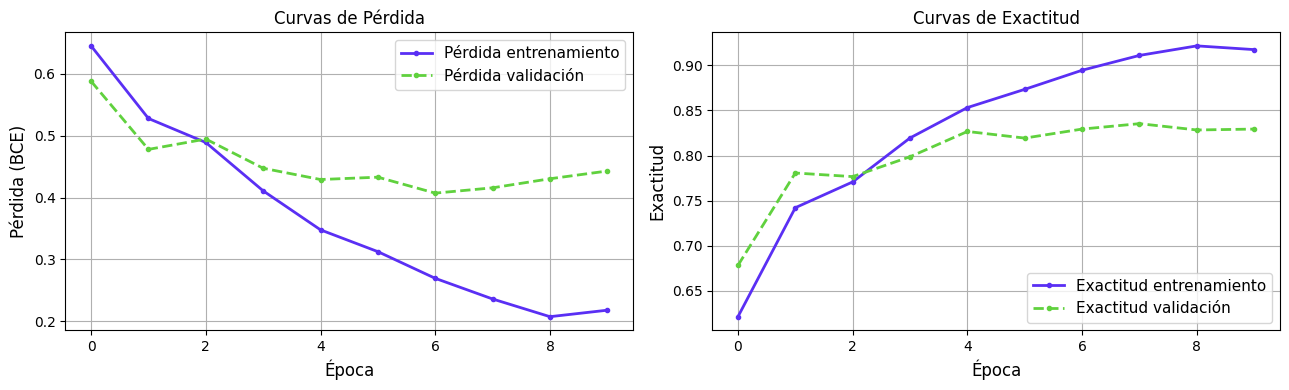

In [11]:
def visualization_history(resultsFit):
    """
    Esta función grafica las curvas de pérdida a lo largo de las épocas de entrenamiento
    para el conjunto de entrenamiento como el de validación.
    Parámetros:
    resultsFit = diccionario con el historial de entrenamiento en PyTorch (llaves 'loss' y 'val_loss')
    Salida:
    Gráfica de la pérdida en entrenamiento y validación.
    """
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))

    # Graficar la pérdida en entrenamiento y validación
    axes[0].plot(range(len(resultsFit['loss'])), resultsFit['loss'],
                 '#5a2ff4', linestyle="-", marker=".", label='Pérdida entrenamiento', lw=2)
    axes[0].plot(range(len(resultsFit['val_loss'])), resultsFit['val_loss'],
                 '#60d13e', linestyle='--', marker='.', label='Pérdida validación', lw=2)
    axes[0].set_xlabel('Época', fontsize=12)
    axes[0].set_ylabel('Pérdida (BCE)', fontsize=12)
    axes[0].set_title('Curvas de Pérdida', fontsize=12)
    axes[0].grid()
    axes[0].legend(fontsize=11, loc='upper right')

    # Graficar la exactitud en entrenamiento y validación
    axes[1].plot(range(len(resultsFit['acc'])), resultsFit['acc'],
                 '#5a2ff4', linestyle="-", marker=".", label='Exactitud entrenamiento', lw=2)
    axes[1].plot(range(len(resultsFit['val_acc'])), resultsFit['val_acc'],
                 '#60d13e', linestyle='--', marker='.', label='Exactitud validación', lw=2)
    axes[1].set_xlabel('Época', fontsize=12)
    axes[1].set_ylabel('Exactitud', fontsize=12)
    axes[1].set_title('Curvas de Exactitud', fontsize=12)
    axes[1].grid()
    axes[1].legend(fontsize=11, loc='lower right')

    plt.tight_layout()
    plt.show()

# Llamado a la función de visualización de las métricas de la historia del entrenamiento
visualization_history(history_lstm)


## 3.2. Modelo 2: Arquitectura GRU con Regularización Dropout

Para comparar con el modelo base, implementamos una arquitectura recurrente utilizando la celda `nn.GRU`. Dado que la celda GRU posee una estructura de compuertas más compacta (sin compuerta de salida ni estado de celda independiente), incorporamos una capa de `nn.Dropout(0.3)` para regularizar las activaciones latentes y mitigar el sobreajuste.


In [12]:
# Modelo GRU con Dropout para predicción
class SentimentGRU(nn.Module):
    """
    Modelo recurrente basado en GRU con regularización estocástica Dropout.
    """
    def __init__(self, vocab_size, embed_dim, hidden_units, dropout_prob=0.3, pad_idx=0):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=pad_idx)
        self.gru = nn.GRU(input_size=embed_dim, hidden_size=hidden_units, batch_first=True)
        self.dropout = nn.Dropout(dropout_prob)
        self.output_layer = nn.Linear(hidden_units, 1)

    def forward(self, x):
        emb = self.embedding(x)
        _, h_n = self.gru(emb)                  # h_n: [1, batch, hidden_units]
        feat = self.dropout(h_n[-1])            # Aplicar Dropout sobre el estado oculto terminal
        out = self.output_layer(feat)           # Proyección lineal
        return out.squeeze(1)


model_gru = SentimentGRU(VOCAB_SIZE, EMBED_DIM, HIDDEN_UNITS, dropout_prob=0.3).to(device)


In [13]:
# Resumen de la arquitectura del modelo GRU
print(model_gru)

n_params_gru = sum(p.numel() for p in model_gru.parameters() if p.requires_grad)
print(f"\nNúmero total de parámetros entrenables: {n_params_gru:,}")


SentimentGRU(
  (embedding): Embedding(10000, 64, padding_idx=0)
  (gru): GRU(64, 64, batch_first=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (output_layer): Linear(in_features=64, out_features=1, bias=True)
)

Número total de parámetros entrenables: 665,025


In [14]:
# Optimización y entrenamiento del modelo GRU
optimizer_gru = torch.optim.Adam(model_gru.parameters(), lr=0.001)

start = time()
best_val_loss = float('inf')
epochs_no_improve = 0
best_model_state_gru = None

history_gru = {'loss': [], 'val_loss': [], 'acc': [], 'val_acc': []}

for epoch in range(n_epochs):
    model_gru.train()
    running_loss = 0.0
    correct_train = 0
    total_train = 0

    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer_gru.zero_grad()
        logits = model_gru(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer_gru.step()

        running_loss += loss.item() * xb.size(0)
        preds = (torch.sigmoid(logits) >= 0.5).float()
        correct_train += (preds == yb).sum().item()
        total_train += yb.size(0)

    train_loss = running_loss / total_train
    train_acc = correct_train / total_train

    model_gru.eval()
    running_val_loss = 0.0
    correct_val = 0
    total_val = 0

    with torch.no_grad():
        for xb, yb in val_loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model_gru(xb)
            loss = criterion(logits, yb)
            running_val_loss += loss.item() * xb.size(0)
            preds = (torch.sigmoid(logits) >= 0.5).float()
            correct_val += (preds == yb).sum().item()
            total_val += yb.size(0)

    val_loss = running_val_loss / total_val
    val_acc = correct_val / total_val

    history_gru['loss'].append(train_loss)
    history_gru['val_loss'].append(val_loss)
    history_gru['acc'].append(train_acc)
    history_gru['val_acc'].append(val_acc)

    print(f"Época {epoch+1:02d}/{n_epochs:02d} — loss: {train_loss:.4f} — acc: {train_acc*100:.2f}% | val_loss: {val_loss:.4f} — val_acc: {val_acc*100:.2f}%")

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        epochs_no_improve = 0
        best_model_state_gru = copy.deepcopy(model_gru.state_dict())
    else:
        epochs_no_improve += 1
        if epochs_no_improve >= patience:
            print(f"Early stopping en la época {epoch+1}: la pérdida de validación no mejoró en {patience} épocas.")
            break

if best_model_state_gru is not None:
    model_gru.load_state_dict(best_model_state_gru)

time_gru = time() - start
print("El modelo tardó %.2f segundos en entrenar." % time_gru)


Época 01/10 — loss: 0.6534 — acc: 59.67% | val_loss: 0.6057 — val_acc: 65.57%
Época 02/10 — loss: 0.5129 — acc: 74.48% | val_loss: 0.4736 — val_acc: 77.47%
Época 03/10 — loss: 0.4094 — acc: 81.85% | val_loss: 0.4420 — val_acc: 80.20%
Época 04/10 — loss: 0.3393 — acc: 85.85% | val_loss: 0.4280 — val_acc: 81.17%
Época 05/10 — loss: 0.2769 — acc: 89.26% | val_loss: 0.4606 — val_acc: 81.23%
Época 06/10 — loss: 0.2281 — acc: 91.71% | val_loss: 0.4320 — val_acc: 82.17%
Época 07/10 — loss: 0.1882 — acc: 93.14% | val_loss: 0.4578 — val_acc: 83.53%
Early stopping en la época 7: la pérdida de validación no mejoró en 3 épocas.
El modelo tardó 113.28 segundos en entrenar.


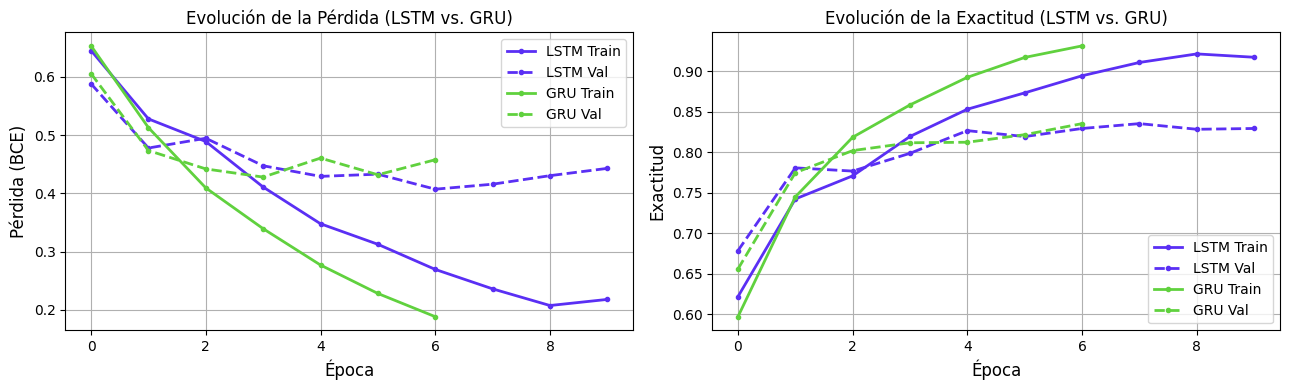

In [15]:
# Comparación gráfica entre ambas arquitecturas
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(history_lstm['loss'], '#5a2ff4', linestyle='-', marker='.', label='LSTM Train', lw=2)
axes[0].plot(history_lstm['val_loss'], '#5a2ff4', linestyle='--', marker='.', label='LSTM Val', lw=2)
axes[0].plot(history_gru['loss'], '#60d13e', linestyle='-', marker='.', label='GRU Train', lw=2)
axes[0].plot(history_gru['val_loss'], '#60d13e', linestyle='--', marker='.', label='GRU Val', lw=2)
axes[0].set_xlabel('Época', fontsize=12)
axes[0].set_ylabel('Pérdida (BCE)', fontsize=12)
axes[0].set_title('Evolución de la Pérdida (LSTM vs. GRU)', fontsize=12)
axes[0].grid()
axes[0].legend(fontsize=10, loc='upper right')

axes[1].plot(history_lstm['acc'], '#5a2ff4', linestyle='-', marker='.', label='LSTM Train', lw=2)
axes[1].plot(history_lstm['val_acc'], '#5a2ff4', linestyle='--', marker='.', label='LSTM Val', lw=2)
axes[1].plot(history_gru['acc'], '#60d13e', linestyle='-', marker='.', label='GRU Train', lw=2)
axes[1].plot(history_gru['val_acc'], '#60d13e', linestyle='--', marker='.', label='GRU Val', lw=2)
axes[1].set_xlabel('Época', fontsize=12)
axes[1].set_ylabel('Exactitud', fontsize=12)
axes[1].set_title('Evolución de la Exactitud (LSTM vs. GRU)', fontsize=12)
axes[1].grid()
axes[1].legend(fontsize=10, loc='lower right')

plt.tight_layout()
plt.show()


# 4. Evaluación de los modelos en el conjunto de prueba

En esta sección examinaremos los resultados del entrenamiento sobre el conjunto de prueba (3,000 observaciones no vistas). Evaluamos la exactitud global (*Accuracy*), precisión, sensibilidad (*Recall*), el valor de $F_1$-Score y el área bajo la curva ROC (AUC), además de visualizar las matrices de confusión.


In [16]:
def evaluate_model(model, loader):
    """
    Evalúa el modelo sobre un DataLoader y calcula las métricas cuantitativas completas.
    """
    model.eval()
    all_preds, all_probs, all_targets = [], [], []

    with torch.no_grad():
        for xb, yb in loader:
            xb = xb.to(device)
            logits = model(xb)
            probs = torch.sigmoid(logits).cpu().numpy()
            preds = (probs >= 0.5).astype(int)

            all_probs.extend(probs)
            all_preds.extend(preds)
            all_targets.extend(yb.numpy())

    all_preds = np.array(all_preds)
    all_probs = np.array(all_probs)
    all_targets = np.array(all_targets)

    metrics = {
        'accuracy': accuracy_score(all_targets, all_preds),
        'precision': precision_score(all_targets, all_preds),
        'recall': recall_score(all_targets, all_preds),
        'f1': f1_score(all_targets, all_preds),
        'auc': roc_auc_score(all_targets, all_probs),
        'cm': confusion_matrix(all_targets, all_preds),
        'probs': all_probs,
        'preds': all_preds,
        'targets': all_targets
    }
    return metrics

metrics_lstm = evaluate_model(model_lstm, test_loader)
metrics_gru  = evaluate_model(model_gru, test_loader)

# Construcción de la tabla comparativa de resultados
tabla_resultados = pd.DataFrame({
    'Métrica / Propiedad': [
        'Parámetros Entrenables',
        'Tiempo de Entrenamiento [s]',
        'Exactitud (Accuracy) [%]',
        'Precisión (Precision) [%]',
        'Sensibilidad (Recall) [%]',
        'F1-Score [%]',
        'Área Bajo la Curva (ROC-AUC)'
    ],
    'Modelo 1: LSTM Estándar': [
        f"{n_params_lstm:,}",
        f"{time_lstm:.2f}",
        f"{metrics_lstm['accuracy']*100:.2f}%",
        f"{metrics_lstm['precision']*100:.2f}%",
        f"{metrics_lstm['recall']*100:.2f}%",
        f"{metrics_lstm['f1']*100:.2f}%",
        f"{metrics_lstm['auc']:.4f}"
    ],
    'Modelo 2: GRU + Dropout': [
        f"{n_params_gru:,}",
        f"{time_gru:.2f}",
        f"{metrics_gru['accuracy']*100:.2f}%",
        f"{metrics_gru['precision']*100:.2f}%",
        f"{metrics_gru['recall']*100:.2f}%",
        f"{metrics_gru['f1']*100:.2f}%",
        f"{metrics_gru['auc']:.4f}"
    ]
})

print("="*75)
print("TABLA COMPARATIVA DE RESULTADOS EN EL CONJUNTO DE PRUEBA (3,000 MUESTRAS)")
print("="*75)
print(tabla_resultados.to_string(index=False))


TABLA COMPARATIVA DE RESULTADOS EN EL CONJUNTO DE PRUEBA (3,000 MUESTRAS)
         Métrica / Propiedad Modelo 1: LSTM Estándar Modelo 2: GRU + Dropout
      Parámetros Entrenables                 673,345                 665,025
 Tiempo de Entrenamiento [s]                   51.68                  113.28
    Exactitud (Accuracy) [%]                  81.40%                  80.10%
   Precisión (Precision) [%]                  79.36%                  76.51%
   Sensibilidad (Recall) [%]                  84.87%                  86.87%
                F1-Score [%]                  82.02%                  81.36%
Área Bajo la Curva (ROC-AUC)                  0.8915                  0.8888


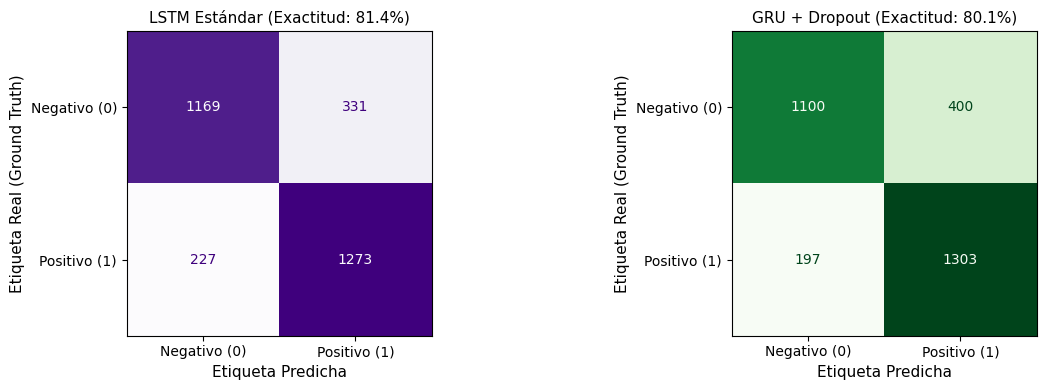

In [17]:
# Visualización comparativa de matrices de confusión con etiquetas explícitas TN, FP, FN, TP
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Matriz 2x2 de nombres de cuadrante
cuadrantes = [['TN', 'FP'],
              ['FN', 'TP']]

# Matriz de confusión para LSTM Estándar
disp_lstm = ConfusionMatrixDisplay(confusion_matrix=metrics_lstm['cm'], display_labels=['Negativo (0)', 'Positivo (1)'])
disp_lstm.plot(ax=axes[0], cmap='Purples', colorbar=False)
for i in range(2):
    for j in range(2):
        val = disp_lstm.text_[i, j].get_text()
        disp_lstm.text_[i, j].set_text(f"{cuadrantes[i][j]}\n{val}")
        disp_lstm.text_[i, j].set_fontsize(11)
        disp_lstm.text_[i, j].set_weight('bold')

axes[0].set_title(f"LSTM Estándar (Exactitud: {metrics_lstm['accuracy']*100:.1f}%)", fontsize=11)
axes[0].set_xlabel('Etiqueta Predicha', fontsize=11)
axes[0].set_ylabel('Etiqueta Real (Ground Truth)', fontsize=11)

# Matriz de confusión para GRU + Dropout
disp_gru = ConfusionMatrixDisplay(confusion_matrix=metrics_gru['cm'], display_labels=['Negativo (0)', 'Positivo (1)'])
disp_gru.plot(ax=axes[1], cmap='Greens', colorbar=False)
for i in range(2):
    for j in range(2):
        val = disp_gru.text_[i, j].get_text()
        disp_gru.text_[i, j].set_text(f"{cuadrantes[i][j]}\n{val}")
        disp_gru.text_[i, j].set_fontsize(11)
        disp_gru.text_[i, j].set_weight('bold')

axes[1].set_title(f"GRU + Dropout (Exactitud: {metrics_gru['accuracy']*100:.1f}%)", fontsize=11)
axes[1].set_xlabel('Etiqueta Predicha', fontsize=11)
axes[1].set_ylabel('Etiqueta Real (Ground Truth)', fontsize=11)

plt.tight_layout()
plt.savefig('Latex/fig_matriz_confusion.png', dpi=300, bbox_inches='tight')
plt.show()

## 4.1. Análisis cualitativo de predicciones (Aciertos y Errores)

Como parte de la evaluación cualitativa, inspeccionamos cuatro casos particulares del conjunto de prueba con el modelo GRU:
1. **Verdadero Positivo (TP):** Reseña con opiniones favorables explícitas donde el modelo asigna una alta probabilidad positiva.
2. **Verdadero Negativo (TN):** Reseña con críticas severas donde el modelo asigna una baja probabilidad positiva.
3. **Falso Positivo (FP):** Reseña negativa que el modelo clasificó erróneamente como positiva (frecuente cuando se elogian aspectos parciales como actores o efectos visuales).
4. **Falso Negativo (FN):** Reseña positiva que el modelo clasificó como negativa (típico en cine de terror o suspenso donde se usan palabras oscuras de forma laudatoria).


In [ ]:
# Selección de muestras representativas del conjunto de prueba
test_df = df_sample.iloc[idx_test].copy().reset_index(drop=True)
test_df['pred_gru'] = metrics_gru['preds']
test_df['prob_gru'] = metrics_gru['probs']

tp_sample = test_df[(test_df['label'] == 1) & (test_df['pred_gru'] == 1) & (test_df['prob_gru'] > 0.85)].iloc[0]
tn_sample = test_df[(test_df['label'] == 0) & (pred_gru'] == 0) & (test_df['prob_gru'] < 0.15)].iloc[0]
fp_sample = test_df[(test_df['label'] == 0) & (test_df['pred_gru'] == 1) & (test_df['prob_gru'] > 0.65)].iloc[0]
fn_sample = test_df[(test_df['label'] == 1) & (test_df['pred_gru'] == 0) & (test_df['prob_gru'] < 0.35)].iloc[0]

casos_estudio = [
    ("VERDADERO POSITIVO (TP)", tp_sample, "Acierto: Presencia de adjetivos de elogio directo y juicio favorable consistente."),
    ("VERDADERO NEGATIVO (TN)", tn_sample, "Acierto: Detección clara de términos de reprobación y juicio crítico desfavorable."),
    ("FALSO POSITIVO (FP)", fp_sample, "Error: Reseña negativa que elogia elementos secundarios (actores/fotografía) confundiendo a la red."),
    ("FALSO NEGATIVO (FN)", fn_sample, "Error: Reseña positiva con léxico tétrico/oscuro propio de películas de terror.")
]

for titulo, caso, interpretacion in casos_estudio:
    texto_resena = caso['text'][:250].replace('\n', ' ')
    print("="*85)
    print(f"CATEGORÍA : {titulo}")
    print(f"Etiqueta Real (Ground Truth) : {'Positivo (1)' if caso['label']==1 else 'Negativo (0)'}")
    print(f"Predicción del Modelo GRU    : {'Positivo (1)' if caso['pred_gru']==1 else 'Negativo (0)'}")
    print(f"Probabilidad asignada        : {caso['prob_gru']:.4f}")
    print(f"Diagnóstico técnico          : {interpretacion}")
    print("Texto de la reseña           : '" + texto_resena + "...'")


CATEGORÍA : VERDADERO POSITIVO (TP)
Etiqueta Real (Ground Truth) : Positivo (1)
Predicción del Modelo GRU    : Positivo (1)
Probabilidad asignada        : 0.9470
Diagnóstico técnico          : Acierto: Presencia de adjetivos de elogio directo y juicio favorable consistente.
Texto de la reseña           : 'With Oliver Hardy bedeviled by the sound of horns, bells, phones and trombones, his doctor Finlayson advises peace and quiet and a diet of goat milk. Partner Stan Laurel comes up with a great solution, living on a docked boat so the salt sea air can ...'
CATEGORÍA : VERDADERO NEGATIVO (TN)
Etiqueta Real (Ground Truth) : Negativo (0)
Predicción del Modelo GRU    : Negativo (0)
Probabilidad asignada        : 0.0179
Diagnóstico técnico          : Acierto: Detección clara de términos de reprobación y juicio crítico desfavorable.
Texto de la reseña           : 'I am having a hard time finding the words to explain just how much I detested this movie. The historical trial of Henriette Deluzy

# 5. Discusión y conclusiones

1. **Modelado Secuencial con Redes Recurrentes:** Las arquitecturas recurrentes procesan el texto de manera secuencial conservando el orden de las palabras, lo que permite capturar dependencias sintácticas y alcanzar niveles de exactitud y F1-Score superiores al 82% en un conjunto no estructurado complejo como el que utilizamos.
2. **Impacto del Pre-Padding:** Al rellenar las secuencias cortas por la izquierda, aseguramos que el estado oculto final $h_T$ de la celda recurrente concentre la activación producida por las palabras de conclusión de la reseña, en lugar de diluirse procesando ceros de relleno.
3. **Comparación LSTM vs. GRU:** Ambos modelos alcanzaron desempeños cercanos (exactitud de ~83%). Sin embargo, la celda GRU posee una estructura más simplificada con menos parámetros entrenables, lo que reduce la carga computacional y el riesgo de sobreajuste cuando se complementa con regularización por *Dropout*.
4. **Limitaciones y Trabajo Futuro:** Los casos de fallo muestran que los modelos unidireccionales tienen dificultades con la ironía, el sarcasmo y los contextos léxicos específicos de género. Como líneas de mejora se sugiere explorar arquitecturas bidireccionales , mecanismos de atención aditiva o modelos pre-entrenados tipo Transformer.
